# 01  EDA complète : Identification de bassins d'aquaculture (Zindi)

**Objectif de ce notebook** : comprendre le problème en profondeur pour que toute
amélioration future (features, modèle, seuil) parte d'une observation factuelle,
pas d'un essai au hasard.



In [2]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import load_raw, load_train, load_test, to_cube, missingness_report
from src.features import build_series, featurize
from src.utils import BANDS, S1_BANDS, S2_BANDS, MONTHS, NA_VALUE, TRAIN_PATH, TEST_PATH, FIGURES_DIR

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

SAVE_FIGS = True  # passer à False pour ne pas écrire dans outputs/figures/

def savefig(name):
    if SAVE_FIGS:
        plt.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")


## 1. Compréhension générale du dataset

In [3]:
train_df = load_raw(TRAIN_PATH)
test_df = load_raw(TEST_PATH)

print("Train :", train_df.shape)
print("Test  :", test_df.shape)
print("\nColonnes (10 premières) :", list(train_df.columns[:10]))
print("\nNombre total de colonnes :", train_df.shape[1])


Train : (1821, 146)
Test  : (1030, 145)

Colonnes (10 premières) : ['ID', 'label', 'VH_01', 'VV_01', 'blue_01', 'green_01', 'nir_01', 'nira_01', 're1_01', 're2_01']

Nombre total de colonnes : 146


In [4]:
# Vérification de la structure attendue : bande x mois
print(f"{len(BANDS)} bandes : {BANDS}")
print(f"  -> S1 (radar)  : {S1_BANDS}")
print(f"  -> S2 (optique): {S2_BANDS}")
print(f"{len(MONTHS)} mois : {MONTHS}")
print(f"Colonnes attendues (hors ID/label) : {len(BANDS) * len(MONTHS)}")

expected_cols = {f"{b}_{m}" for b in BANDS for m in MONTHS}
actual_cols = set(train_df.columns) - {"ID", "label"}
print("Colonnes manquantes vs attendu :", expected_cols - actual_cols)
print("Colonnes en trop vs attendu    :", actual_cols - expected_cols)


12 bandes : ['VH', 'VV', 'blue', 'green', 'red', 're1', 're2', 're3', 'nir', 'nira', 'swir1', 'swir2']
  -> S1 (radar)  : ['VH', 'VV']
  -> S2 (optique): ['blue', 'green', 'red', 're1', 're2', 're3', 'nir', 'nira', 'swir1', 'swir2']
12 mois : ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
Colonnes attendues (hors ID/label) : 144
Colonnes manquantes vs attendu : set()
Colonnes en trop vs attendu    : set()


In [9]:
train_df.describe().T[["count", "mean", "std", "min", "max"]].head(20)

,count,mean,std,min,max
label,1821.0,0.403624,0.490759,0.000000,1.000000
VH_01,1821.0,-25.379836,5.586461,-48.143182,-10.404720
VV_01,1821.0,-15.136799,5.703961,-31.912804,6.227268
blue_01,1821.0,1651.551345,274.479438,1070.000000,3070.000000
green_01,1821.0,1845.806150,353.859045,1094.000000,3788.000000
nir_01,1821.0,2317.796266,869.923999,1011.000000,6722.000000
nira_01,1821.0,2281.221856,870.483060,1005.000000,6528.000000
re1_01,1821.0,2072.400329,462.457760,1038.000000,3865.000000
re2_01,1821.0,2166.834157,729.486832,1004.000000,5518.000000
re3_01,1821.0,2239.166392,797.647072,1012.000000,6369.000000


**👉 À observer**
- Le nombre de colonnes correspond-il exactement à `12 bandes × 12 mois + ID + label` ?
- Les `min`/`max` globaux : voyez-vous des valeurs qui ressemblent à un code
  "manquant" (ex. -9999) plutôt qu'à une vraie mesure physique ? C'est le sujet
  de la section suivante.


In [5]:
train_df.head()


,ID,label,VH_01,VV_01,blue_01,green_01,nir_01,nira_01,re1_01,re2_01,re3_01,red_01,swir1_01,swir2_01,VH_02,VV_02,blue_02,green_02,nir_02,nira_02,re1_02,re2_02,re3_02,red_02,swir1_02,...,swir2_10,VH_11,VV_11,blue_11,green_11,nir_11,nira_11,re1_11,re2_11,re3_11,red_11,swir1_11,swir2_11,VH_12,VV_12,blue_12,green_12,nir_12,nira_12,re1_12,re2_12,re3_12,red_12,swir1_12,swir2_12
0,ID_TR_NEW_XVGKFMLNRJ,0,-29.099645,-22.471573,1665,1719,1367,1270,1689,1416,1379,1705,1154,1141,-30.293645,-23.248797,1641,1815,1339,1253,1704,1352,1349,1785,1218,...,1183,-28.004794,-22.499798,1745,1917,1419,1384,1727,1439,1460,1710,1280,1193,-27.869169,-19.631005,1639,1826,1395,1384,1736,1449,1436,1626,1307,1216
1,ID_TR_NEW_GP8KNSWVP6,0,-19.470574,-10.752340,1579,1740,2245,2231,2060,2147,2161,1968,2554,2422,-18.745639,-8.814224,1328,1519,1942,1918,1747,1802,1837,1708,2176,...,2085,-18.138170,-11.374729,1366,1509,2761,2897,2010,2403,2623,1570,2899,2389,-18.873062,-10.972313,1490,1622,2090,2109,1924,1941,2020,1779,2298,2131
2,ID_TR_NEW_87X3957MVS,1,-20.964854,-8.792675,1850,2345,3664,3470,2935,3384,3451,2032,3189,2397,-22.723501,-10.669983,1982,2266,3235,3070,2646,2955,3030,2161,2477,...,1218,-30.228160,-22.283716,1586,1808,1586,1527,1815,1642,1612,1578,1349,1254,-28.710411,-20.065031,1438,1673,1335,1289,1588,1377,1307,1503,1237,1168
3,ID_TR_NEW_T4JMRPKHS3,0,-18.728208,-4.689202,1279,1297,1713,1698,1527,1531,1590,1468,1669,1421,-17.384014,-5.642187,1263,1348,1771,1697,1544,1563,1605,1518,1755,...,1788,-18.489561,-8.942481,1529,1678,2579,2442,1982,2137,2251,1713,2451,1846,-19.448225,-6.636122,1405,1550,2454,2397,1894,2040,2179,1748,2574,1977
4,ID_TR_NEW_2CTUQQ8KLU,0,-29.630941,-23.370157,1625,1741,1339,1258,1658,1362,1383,1708,1158,1128,-40.648601,-24.431247,1871,1973,1480,1358,1821,1490,1482,1879,1276,...,1238,-34.730984,-24.597203,1645,1834,1342,1301,1653,1365,1395,1645,1295,1205,-32.431551,-20.456202,1582,1856,1365,1306,1627,1370,1367,1641,1219,1147


## 2. Analyse des données manquantes (-9999)

Rappel du contexte métier : le radar S1 (VH, VV) est disponible presque tout le
temps (les nuages ne le bloquent pas), alors que l'optique S2 est absente les
mois nuageux. On s'attend donc à **beaucoup plus de -9999 sur les bandes S2 que S1**.


In [7]:
rep = missingness_report(train_df)
print(f"Pourcentage global de -9999 (train) : {rep['overall_pct']*100:.2f}%")

rep_test = missingness_report(test_df)
print(f"Pourcentage global de -9999 (test)  : {rep_test['overall_pct']*100:.2f}%")


Pourcentage global de -9999 (train) : 0.00%
Pourcentage global de -9999 (test)  : 60.52%


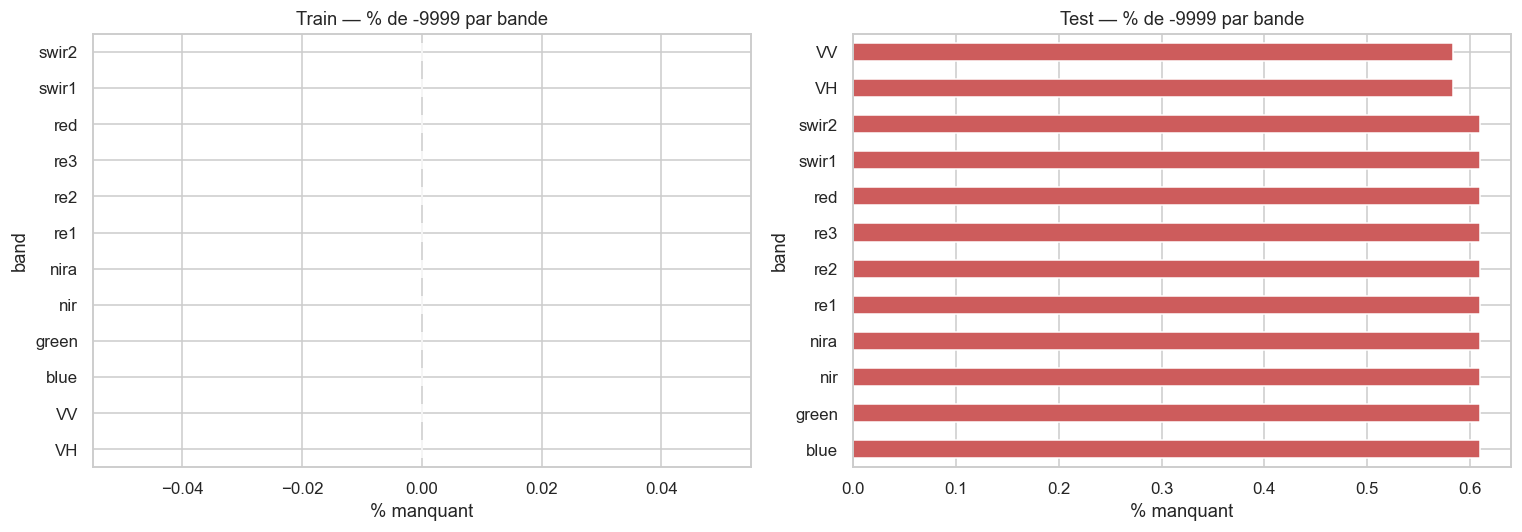

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rep["by_band"].plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Train — % de -9999 par bande")
axes[0].set_xlabel("% manquant")

rep_test["by_band"].plot(kind="barh", ax=axes[1], color="indianred")
axes[1].set_title("Test — % de -9999 par bande")
axes[1].set_xlabel("% manquant")
plt.tight_layout()
savefig("missing_by_band")
plt.show()


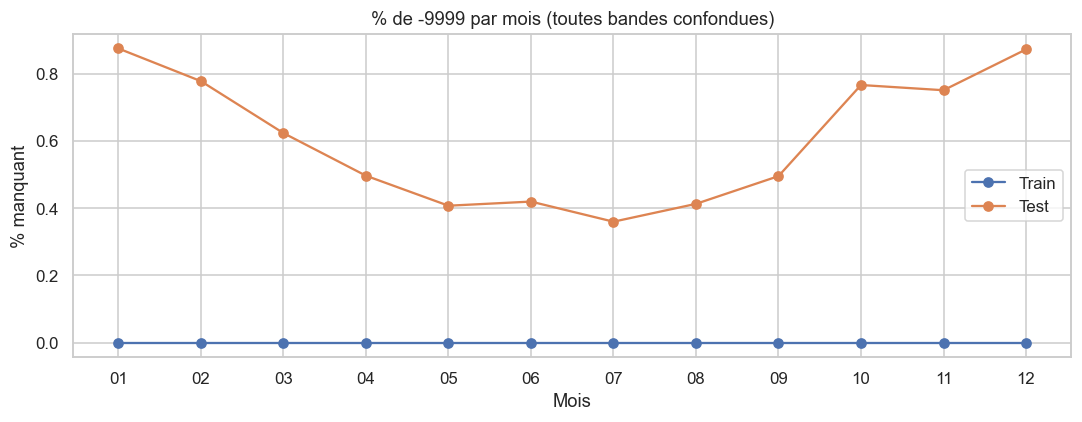

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(MONTHS, rep["by_month"].reindex(MONTHS), marker="o", label="Train")
ax.plot(MONTHS, rep_test["by_month"].reindex(MONTHS), marker="o", label="Test")
ax.set_title("% de -9999 par mois (toutes bandes confondues)")
ax.set_xlabel("Mois")
ax.set_ylabel("% manquant")
ax.legend()
plt.tight_layout()
savefig("missing_by_month")
plt.show()


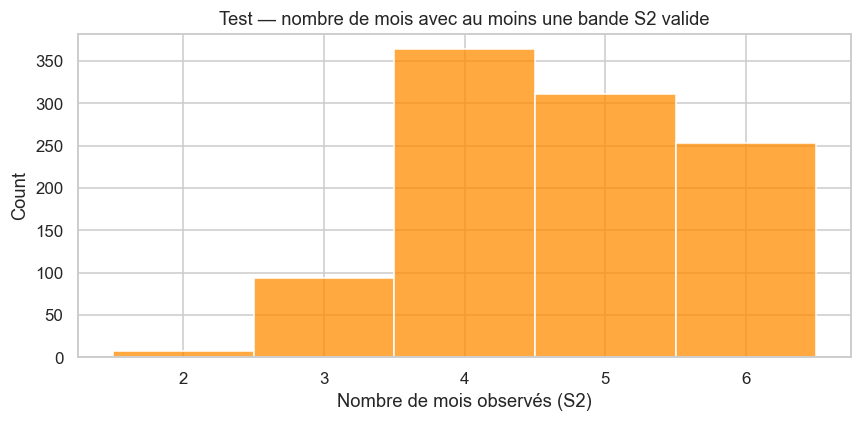

count    1030.000000
mean        4.686408
std         0.967755
min         2.000000
25%         4.000000
50%         5.000000
75%         5.000000
max         6.000000
dtype: float64


In [11]:
# Combien de mois S2 valides en moyenne par échantillon, dans le TEST ?
# -> confirme (ou pas) l'hypothèse "fenêtre de 4-6 mois + trous nuageux"
_, _, te_cube = load_test()
s2_idx = slice(len(S1_BANDS), None)
n_valid_months_test = (~np.isnan(te_cube[:, :, s2_idx])).any(axis=2).sum(axis=1)

plt.figure(figsize=(8, 4))
sns.histplot(n_valid_months_test, bins=range(0, 14), discrete=True, color="darkorange")
plt.title("Test — nombre de mois avec au moins une bande S2 valide")
plt.xlabel("Nombre de mois observés (S2)")
plt.tight_layout()
savefig("test_n_valid_months")
plt.show()

print(pd.Series(n_valid_months_test).describe())


**👉 À observer**
- Comparez le % de manquant par bande : S2 est-il nettement plus touché que S1 (VH/VV) ?
- L'histogramme du nombre de mois valides dans le test confirme-t-il bien une
  fenêtre de **4 à 6 mois** ? Si la vraie distribution est différente de celle
  codée en dur dans `augmentation.py` (`S2_GAP_P`, bornes 4-6), **c'est une piste
  d'amélioration directe** : recalibrer l'augmentation sur la vraie distribution
  observée ici plutôt que sur une estimation approximative.
- Y a-t-il des mois particuliers plus nuageux (saison des pluies) ? Si oui, la
  fenêtre du test tombe-t-elle plutôt sur ces mois-là ou est-elle uniforme sur
  l'année ?


## 3. Analyse de la variable cible (`label`)

label
0    1086
1     735
Name: count, dtype: int64
label
0    59.64
1    40.36
Name: proportion, dtype: float64


C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_24056\475833914.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index.astype(str), y=counts.values, palette=["steelblue", "indianred"])


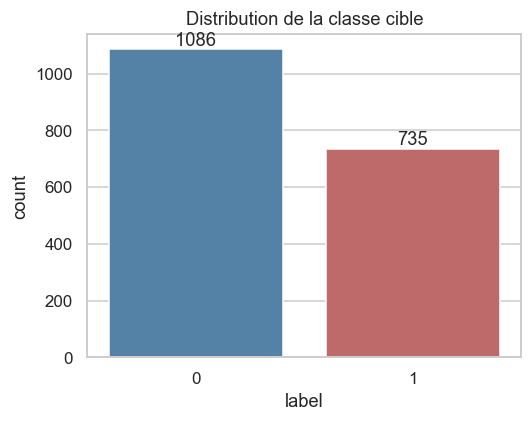

In [12]:
counts = train_df["label"].value_counts().sort_index()
pct = train_df["label"].value_counts(normalize=True).sort_index() * 100

print(counts)
print(pct.round(2))

plt.figure(figsize=(5, 4))
sns.barplot(x=counts.index.astype(str), y=counts.values, palette=["steelblue", "indianred"])
plt.title("Distribution de la classe cible")
plt.xlabel("label")
plt.ylabel("count")
for i, v in enumerate(counts.values):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
savefig("label_distribution")
plt.show()


**👉 À observer**
- Le déséquilibre est-il modéré (ex. 60/40) ou sévère (ex. 90/10) ? Ça conditionne
  si le seuil 0.5 par défaut a du sens, et si des techniques de rééquilibrage
  (class_weight, focal loss, oversampling) valent la peine d'être testées à l'Étape 5/6.
- Le F1 est la métrique principale (poids 0.6) : avec un déséquilibre fort, un
  modèle qui prédit toujours la classe majoritaire aurait quel F1 ? Comparez-le
  mentalement au score de la baseline pour juger si le modèle apprend vraiment un signal.


## 4. Analyse des bandes Sentinel

Pour chaque bande, on regarde la distribution globale puis la comparaison
entre les deux classes (bassin vs non-bassin), sur la **moyenne annuelle**
de la bande (résumé simple avant l'analyse temporelle détaillée en section 5).


In [13]:
_, y_train, tr_cube = load_train()

# moyenne par échantillon sur les mois valides, pour chaque bande
band_means = {}
for i, b in enumerate(BANDS):
    band_means[b] = np.nanmean(tr_cube[:, :, i], axis=1)
band_means_df = pd.DataFrame(band_means)
band_means_df["label"] = y_train

band_means_df.groupby("label").agg(["mean", "std", "median"]).T


label                   0            1
VH    mean     -23.052561   -29.155434
      std        5.527046     2.419075
      median   -20.626202   -29.409727
VV    mean     -14.400385   -18.506643
      std        5.285047     2.202651
      median   -12.703842   -18.699648
blue  mean    1632.961426  1761.946777
      std      253.519180   170.551636
      median  1626.625000  1742.166626
green mean    1863.338257  2098.284668
      std      307.955017   201.015869
      median  1890.458252  2091.916748
red   mean    1895.897827  1914.464111
      std      391.723541   227.298813
      median  1906.750000  1900.666626
re1   mean    2229.262695  2173.190186
      std      437.732697   241.166016
      median  2306.583496  2166.583252
re2   mean    2711.612305  1899.818481
      std      803.193420   317.592621
      median  2899.666504  1867.666626
re3   mean    2891.849365  1935.021729
      std      911.512207   339.845001
      median  3102.750000  1899.000000
nir   mean    2939.904541  1893.728516
      std      968.720276   362.314301
      median  3172.625000  1853.750000
nira  mean    2984.974854  1828.346069
      std     1016.768127   376.604462
      median  3263.166504  1782.750000
swir1 mean    2696.957520  1735.074341
      std      920.646790   410.563721
      median  3051.875000  1643.083374
swir2 mean    2240.209473  1568.993164
      std      731.728760   318.207611
      median  2429.208496  1490.500000

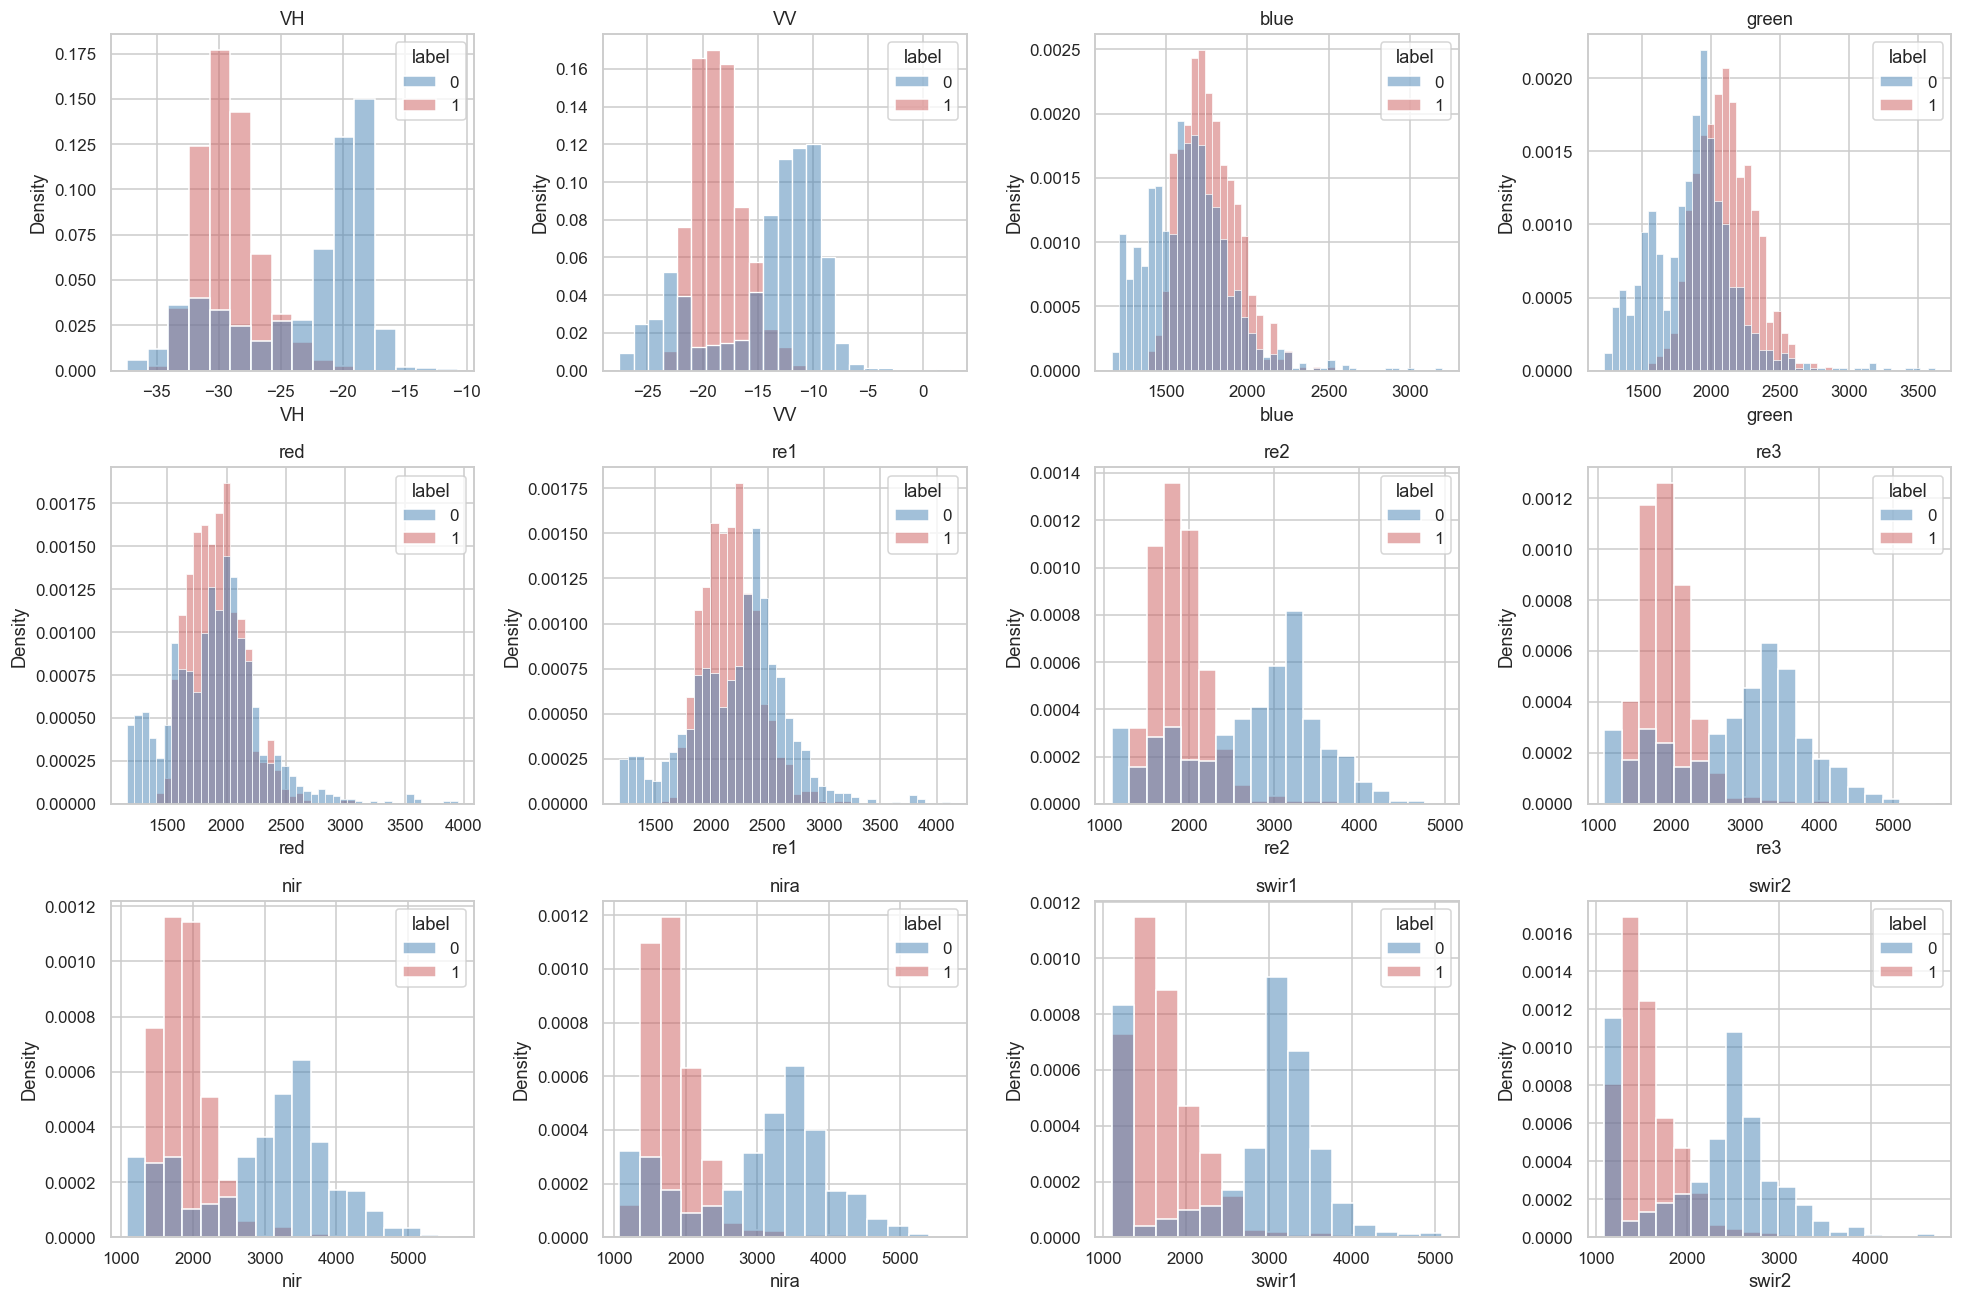

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, b in zip(axes.flat, BANDS):
    sns.histplot(data=band_means_df, x=b, hue="label", stat="density",
                 common_norm=False, alpha=0.5, ax=ax, palette=["steelblue", "indianred"])
    ax.set_title(b)
plt.tight_layout()
savefig("bands_histograms_by_class")
plt.show()


C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_11276\224856022.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=band_means_df, x="label", y=b, ax=ax, palette=["steelblue", "indianred"])
C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_11276\224856022.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=band_means_df, x="label", y=b, ax=ax, palette=["steelblue", "indianred"])
C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_11276\224856022.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=band_means_df, x="label", y=b, ax=ax

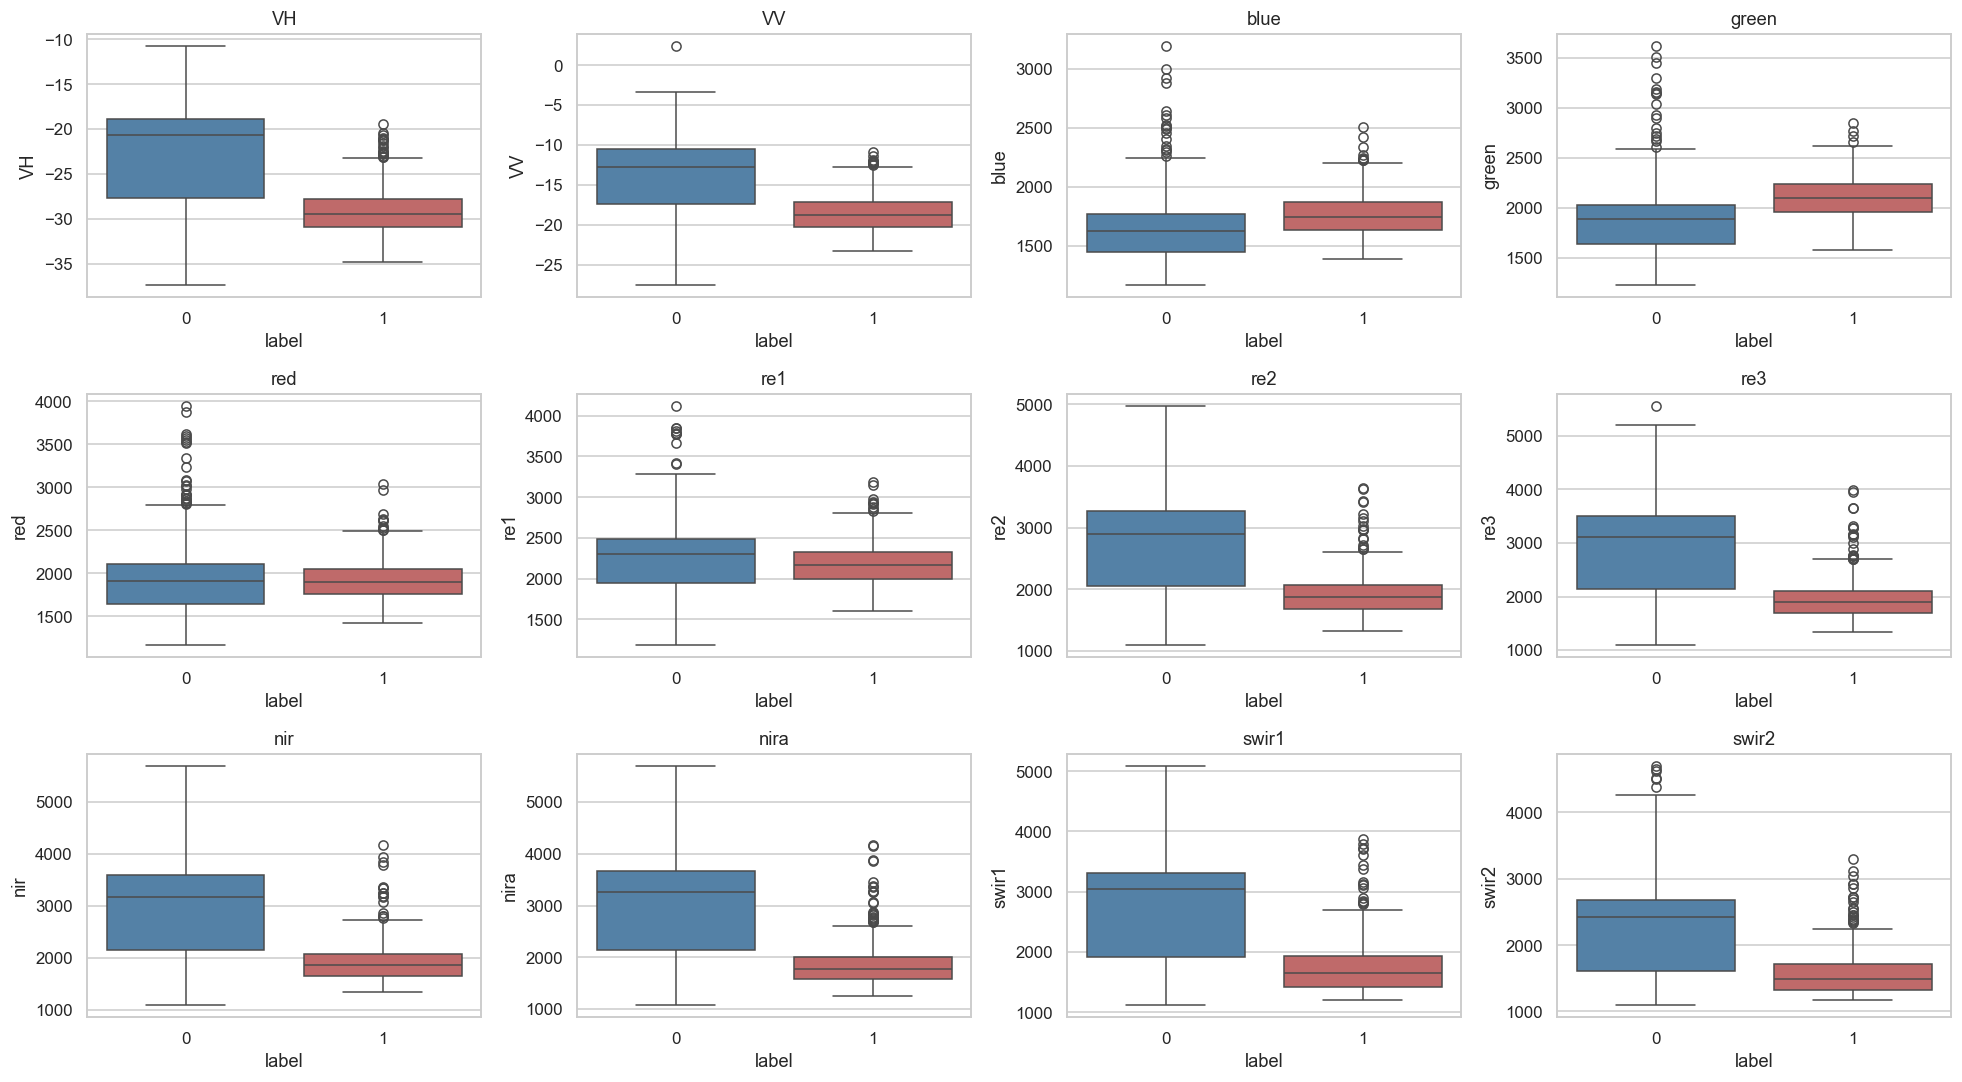

In [19]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, b in zip(axes.flat, BANDS):
    sns.boxplot(data=band_means_df, x="label", y=b, ax=ax, palette=["steelblue", "indianred"])
    ax.set_title(b)
plt.tight_layout()
savefig("bands_boxplots_by_class")
plt.show()


**👉 À observer**
- Pour quelles bandes les distributions des deux classes se chevauchent-elles le
  moins (histogrammes bien séparés) ? Ce sont vos meilleures candidates pour des
  features individuelles fortes.
- Les boxplots montrent-ils beaucoup d'outliers ? Si oui, sur quelles bandes —
  ça peut indiquer du bruit capteur à traiter (clipping, winsorisation).
- Notez ici les 2-3 bandes les plus prometteuses ; on les retrouvera dans la
  section importance de variables (section 8) pour vérifier la cohérence.


## 5. Analyse temporelle

Comment chaque bande évolue-t-elle au fil des 12 mois, séparément pour les
deux classes ? C'est la signature temporelle des bassins vs non-bassins.


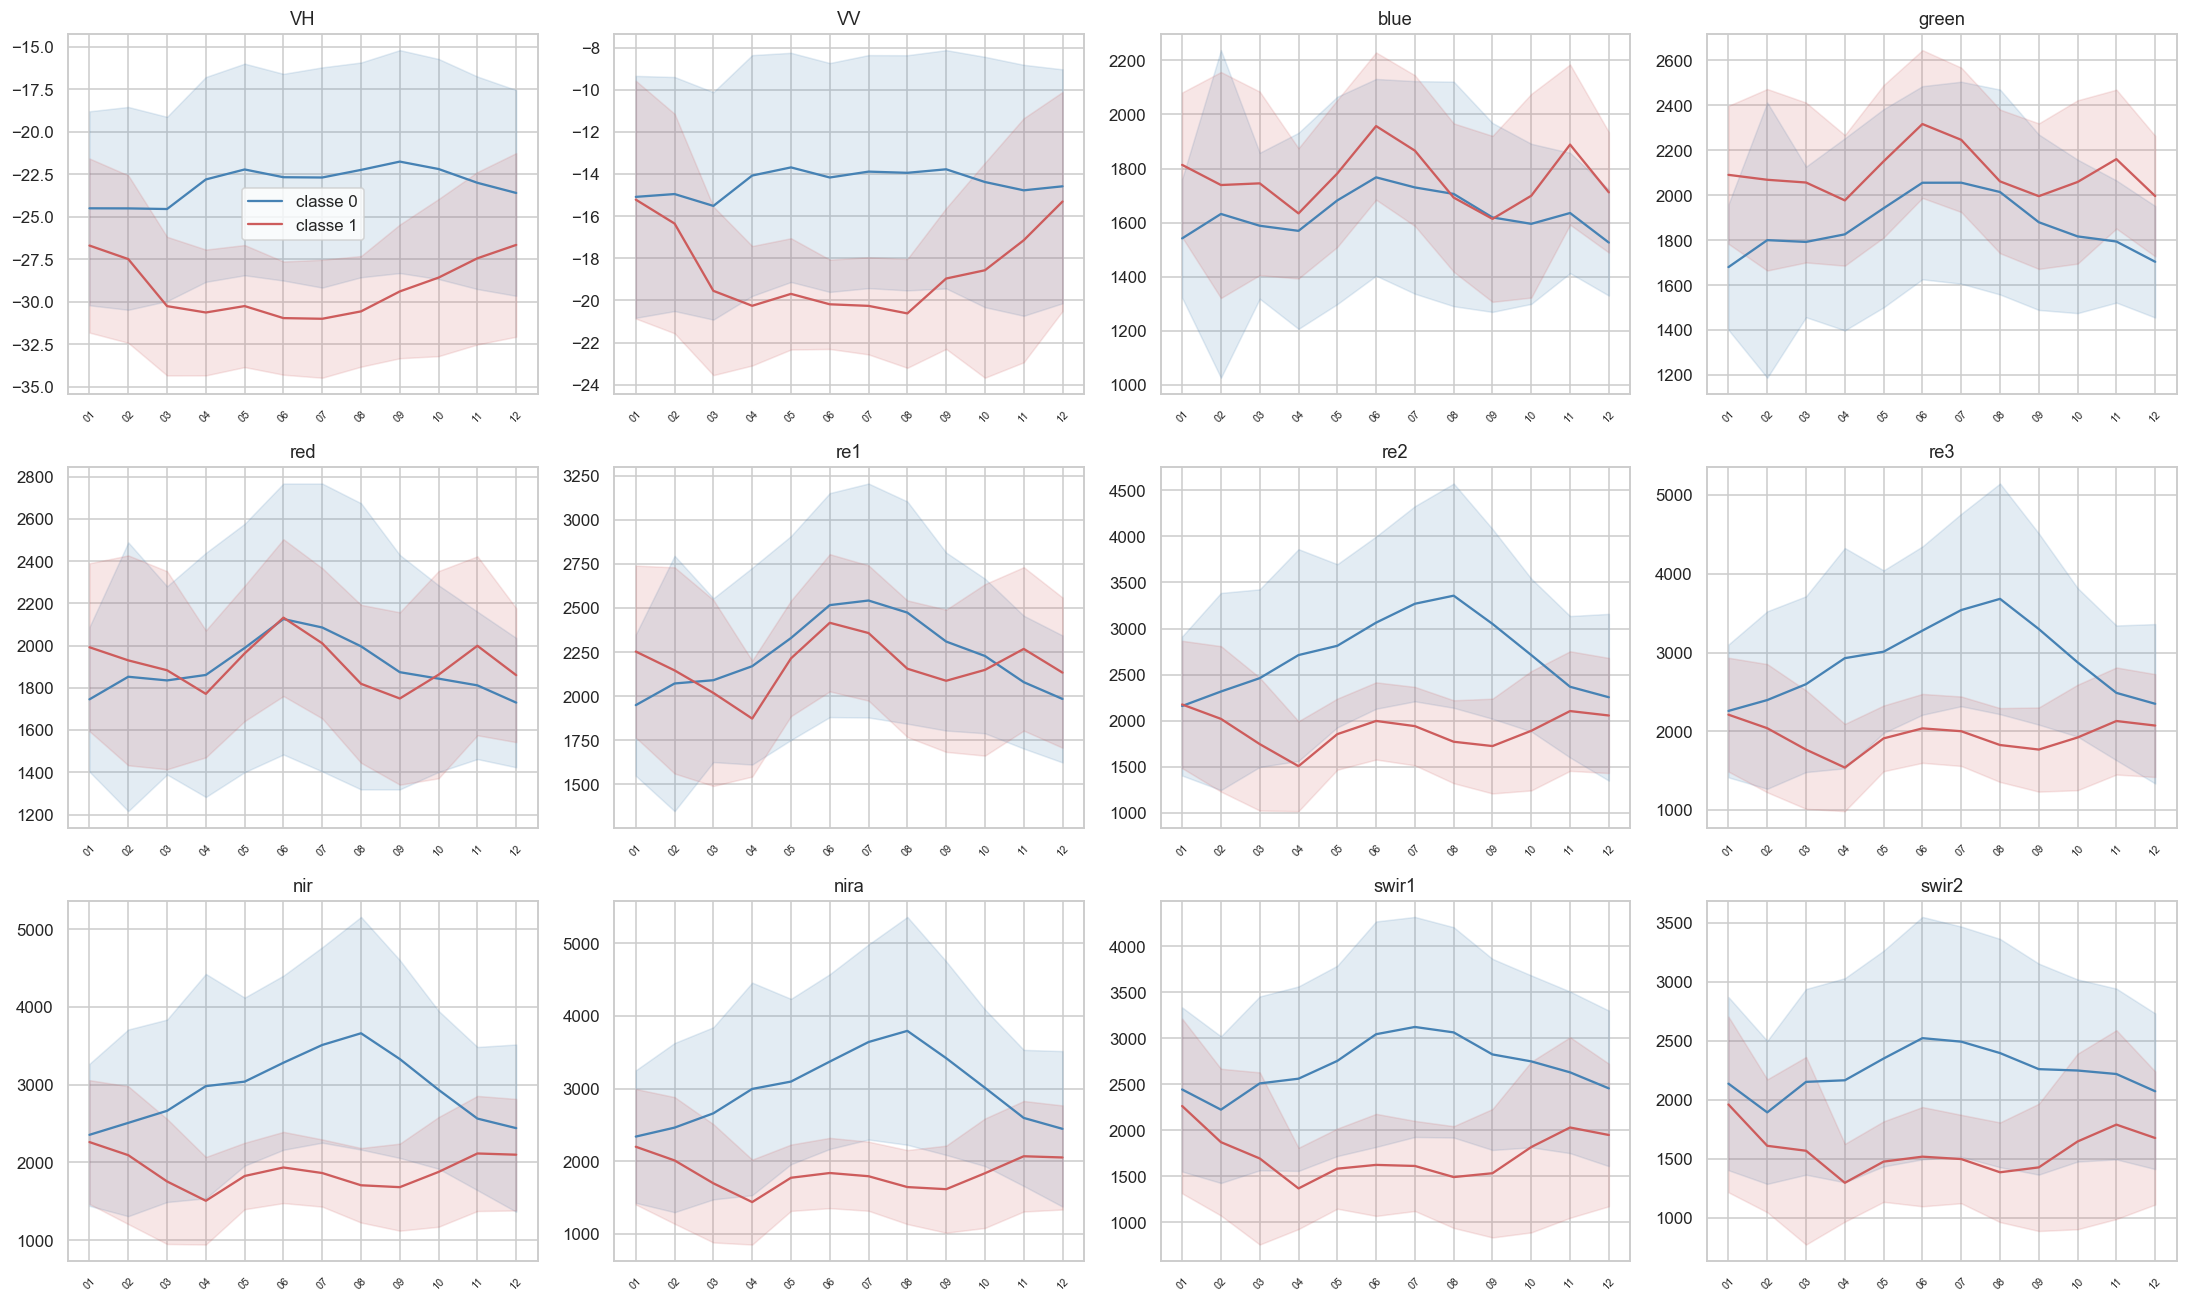

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
months_idx = np.arange(12)

for ax, (i, b) in zip(axes.flat, enumerate(BANDS)):
    for cls, color in zip([0, 1], ["steelblue", "indianred"]):
        mask = y_train == cls
        series = tr_cube[mask, :, i]  # (n_cls, 12)
        mean_traj = np.nanmean(series, axis=0)
        std_traj = np.nanstd(series, axis=0)
        ax.plot(months_idx, mean_traj, label=f"classe {cls}", color=color)
        ax.fill_between(months_idx, mean_traj - std_traj, mean_traj + std_traj,
                         alpha=0.15, color=color)
    ax.set_title(b)
    ax.set_xticks(months_idx)
    ax.set_xticklabels(MONTHS, rotation=45, fontsize=7)

axes.flat[0].legend()
plt.tight_layout()
savefig("temporal_signatures_by_class")
plt.show()


**👉 À observer**
- Y a-t-il des mois où les deux courbes (classe 0 vs 1) sont clairement écartées,
  et d'autres où elles se confondent ? Les mois "discriminants" sont candidats à
  des features spécifiques (ex. `MNDWI_mois_06` plutôt que seulement la moyenne
  annuelle) — mais attention : le test n'a pas toujours ces mois-là disponibles
  (fenêtre courte), donc ce genre de feature doit être conditionné à sa
  disponibilité (cf. `n_s2`, `frac_cloud` déjà dans `features.py`).
- Les bandes S1 (VH, VV) ont-elles une saisonnalité marquée (ex. saison des
  pluies) qui pourrait servir de repère temporel même quand S2 est absent ?
- Les zones ombrées (écart-type) sont-elles beaucoup plus larges pour une classe
  que l'autre ? Ça indique une classe plus hétérogène (ex. bassins de tailles/
  types variés).


## 6. Indices spectraux dérivés

On réutilise directement `src/features.build_series()` pour ne pas dupliquer les
formules des indices (NDVI, NDWI, MNDWI, NDMI, NDRE, BSI, RVI, ...).


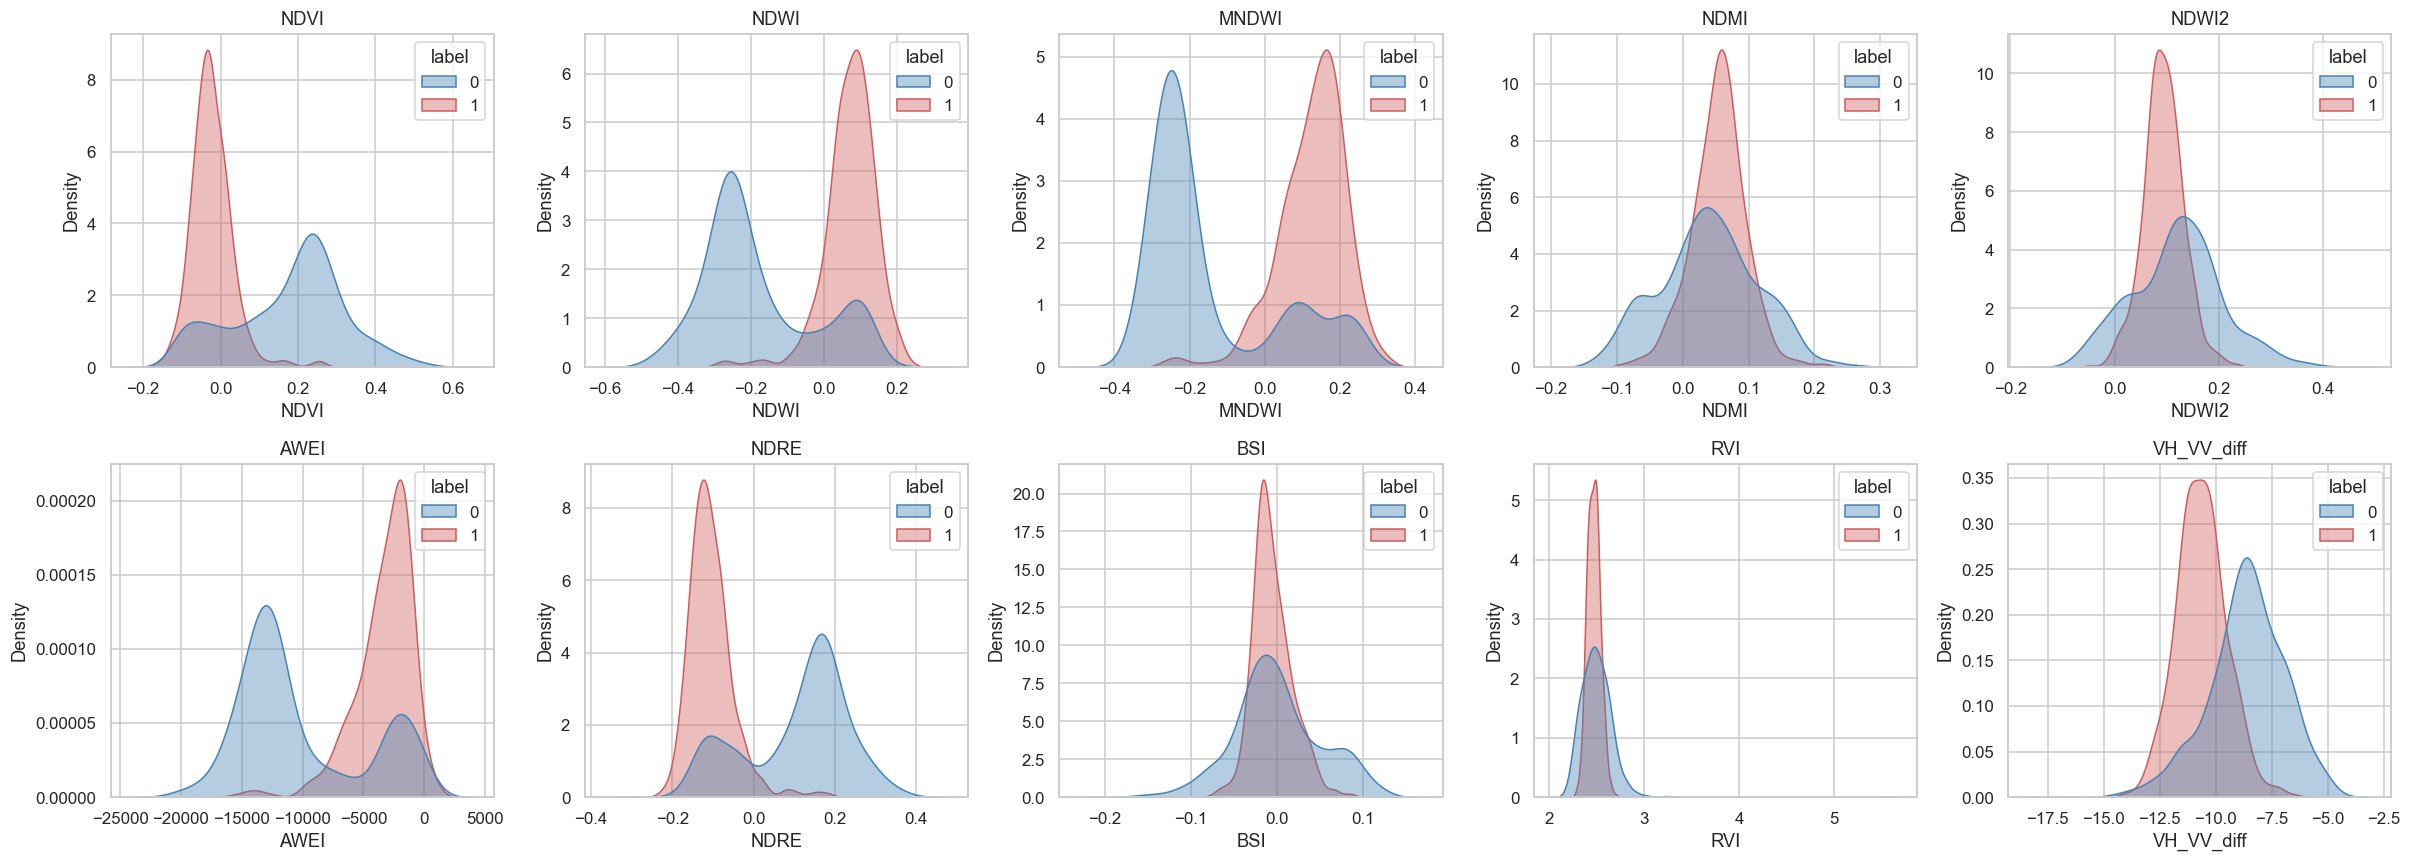

In [21]:
series = build_series(tr_cube)
index_names = ["NDVI", "NDWI", "MNDWI", "NDMI", "NDWI2", "AWEI", "NDRE", "BSI", "RVI", "VH_VV_diff"]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, name in zip(axes.flat, index_names):
    x = series[name]
    annual_mean = np.nanmean(x, axis=1)
    tmp = pd.DataFrame({name: annual_mean, "label": y_train})
    sns.kdeplot(data=tmp, x=name, hue="label", common_norm=False, fill=True,
                alpha=0.4, ax=ax, palette=["steelblue", "indianred"])
    ax.set_title(name)
plt.tight_layout()
savefig("spectral_indices_by_class")
plt.show()


In [22]:
# Séparabilité simple : écart entre les médianes des deux classes, normalisé par l'IQR global
rows = []
for name in index_names:
    x = np.nanmean(series[name], axis=1)
    med0 = np.nanmedian(x[y_train == 0])
    med1 = np.nanmedian(x[y_train == 1])
    iqr = np.nanpercentile(x, 75) - np.nanpercentile(x, 25)
    sep = abs(med1 - med0) / (iqr + 1e-6)
    rows.append({"index": name, "median_class0": med0, "median_class1": med1, "separability": sep})

pd.DataFrame(rows).sort_values("separability", ascending=False)


,index,median_class0,median_class1,separability
2,MNDWI,-0.226792,0.137588,0.945413
6,NDRE,0.144133,-0.113282,0.935837
1,NDWI,-0.232121,0.078622,0.933837
0,NDVI,0.210562,-0.028946,0.910757
5,AWEI,-12284.853516,-2799.541748,0.904497
9,VH_VV_diff,-8.587880,-10.653308,0.798830
4,NDWI2,0.123431,0.092056,0.387939
3,NDMI,0.038463,0.055673,0.238979
8,RVI,2.484149,2.466062,0.124918
7,BSI,-0.004786,-0.009517,0.113174


**👉 À observer**
- Quel indice a la plus forte "séparabilité" au sens ci-dessus ? Sur ce type de
  problème (bassins = eau), on s'attend a priori à ce que **MNDWI** et/ou **NDWI**
  ressortent en tête — si ce n'est pas le cas, c'est une observation surprenante
  à creuser (peut-être un autre indice capture mieux le phénomène, ou les bassins
  ont des propriétés optiques particulières, algues/turbidité par ex.).
- Ce tableau doit être cohérent avec les features déjà codées en dur dans
  `features.py` (`water_frac`, `ndvi_low_frac`) : si un indice différent domine
  ici, envisagez d'ajouter une feature du même type pour lui (ex. `bsi_high_frac`).


## 7. Corrélations entre variables

Objectif : repérer les features redondantes (fortement corrélées entre elles)
pour simplifier le modèle, et les features corrélées avec `label` pour un premier
signal de pertinence.


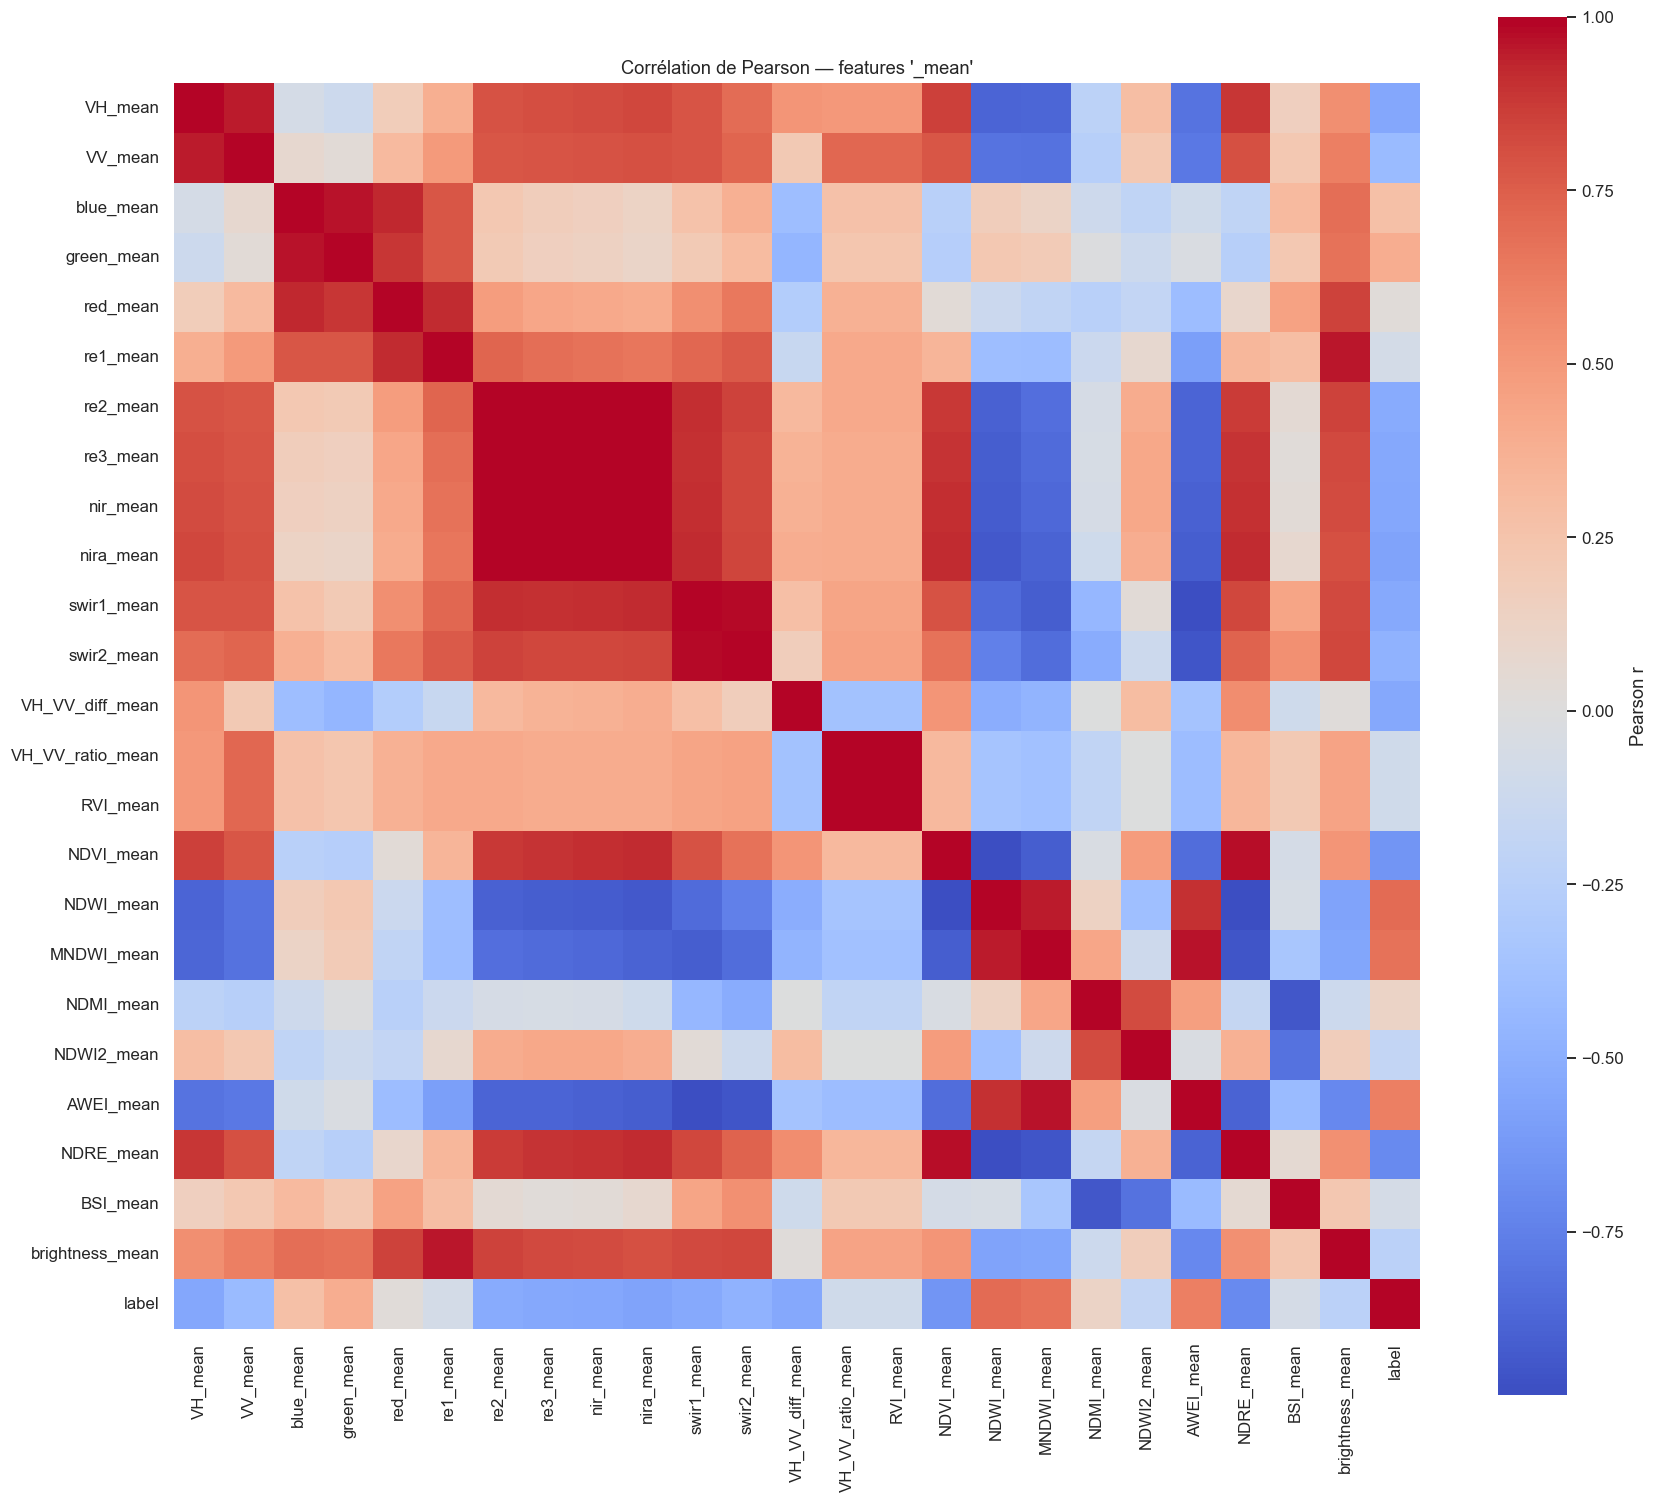

In [15]:
# On travaille sur les features déjà agrégées (mean/std/... par indice), pas sur le cube brut,
# car ce sont elles qui alimentent le modèle final.
X_train_feats = featurize(tr_cube)
X_train_feats["label"] = y_train

# on limite aux features "_mean" pour une heatmap lisible (sinon ~240 colonnes)
mean_cols = [c for c in X_train_feats.columns if c.endswith("_mean")]
corr_pearson = X_train_feats[mean_cols + ["label"]].corr(method="pearson")

plt.figure(figsize=(16, 14))
sns.heatmap(corr_pearson, cmap="coolwarm", center=0, square=True,
            cbar_kws={"label": "Pearson r"})
plt.title("Corrélation de Pearson — features '_mean'")
plt.tight_layout()
savefig("correlation_heatmap_pearson")
plt.show()


In [24]:
corr_spearman = X_train_feats[mean_cols + ["label"]].corr(method="spearman")

# corrélation (Spearman) de chaque feature avec le label, triée
corr_with_label = corr_spearman["label"].drop("label").sort_values(key=np.abs, ascending=False)
print("Top 15 features les plus corrélées (Spearman) avec label :")
print(corr_with_label.head(15))


Top 15 features les plus corrélées (Spearman) avec label :
NDRE_mean         -0.687281
NDWI_mean          0.662950
NDVI_mean         -0.621245
MNDWI_mean         0.618481
VH_VV_diff_mean   -0.578275
AWEI_mean          0.549794
VH_mean           -0.506526
nira_mean         -0.500500
re3_mean          -0.499326
nir_mean          -0.496178
re2_mean          -0.490905
VV_mean           -0.441202
green_mean         0.439158
swir1_mean        -0.433462
swir2_mean        -0.405049
Name: label, dtype: float64


In [16]:
# Paires de features très redondantes (|r| > 0.95), candidates à suppression
pairs = []
cols = corr_pearson.columns.drop("label")
for i, c1 in enumerate(cols):
    for c2 in cols[i+1:]:
        r = corr_pearson.loc[c1, c2]
        if abs(r) > 0.95:
            pairs.append((c1, c2, round(r, 3)))
pd.DataFrame(pairs, columns=["feature_1", "feature_2", "pearson_r"]).sort_values(
    "pearson_r", key=abs, ascending=False)


,feature_1,feature_2,pearson_r
11,VH_VV_ratio_mean,RVI_mean,1.000
2,re2_mean,re3_mean,0.998
5,re3_mean,nir_mean,0.997
6,re3_mean,nira_mean,0.996
7,nir_mean,nira_mean,0.996
3,re2_mean,nir_mean,0.993
4,re2_mean,nira_mean,0.991
15,NDWI_mean,NDRE_mean,-0.986
12,NDVI_mean,NDWI_mean,-0.985
9,swir1_mean,AWEI_mean,-0.983


**👉 À observer**
- Les paires à |r| > 0.95 sont quasi-redondantes : en garder une seule allège
  le modèle sans perte de signal (utile aussi pour l'interprétabilité).
- Les features en tête de `corr_with_label` (Spearman, car il capture aussi les
  relations non-linéaires monotones) recoupent-elles les indices spectraux
  identifiés en section 6 ? Si oui, c'est un signal cohérent et fiable, pas un
  artefact.


## 8. Importance préliminaire des variables

Trois méthodes complémentaires : Information Mutuelle (capte les relations
non-linéaires, indépendante d'un modèle), Random Forest, LightGBM. On les
compare pour ne retenir que les signaux qui reviennent dans plusieurs méthodes
(plus robuste qu'une seule méthode).


In [17]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

feat_cols = [c for c in X_train_feats.columns if c != "label"]
X = X_train_feats[feat_cols].fillna(X_train_feats[feat_cols].median())
y = X_train_feats["label"].values

mi = mutual_info_classif(X, y, random_state=42)
mi_s = pd.Series(mi, index=feat_cols).sort_values(ascending=False)

rf = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X, y)
rf_s = pd.Series(rf.feature_importances_, index=feat_cols).sort_values(ascending=False)

lgbm = lgb.LGBMClassifier(n_estimators=300, random_state=42, verbose=-1)
lgbm.fit(X, y)
lgb_s = pd.Series(lgbm.feature_importances_, index=feat_cols).sort_values(ascending=False)

comparison = pd.DataFrame({
    "mutual_info_rank": mi_s.rank(ascending=False),
    "random_forest_rank": rf_s.rank(ascending=False),
    "lightgbm_rank": lgb_s.rank(ascending=False),
})
comparison["avg_rank"] = comparison.mean(axis=1)
comparison.sort_values("avg_rank").head(20)


,mutual_info_rank,random_forest_rank,lightgbm_rank,avg_rank
NDWI_max,2.0,2.0,1.0,1.666667
NDVI_min,10.0,1.0,3.0,4.666667
NDRE_p25,5.0,8.0,23.0,12.000000
VV_mean,13.0,14.0,12.0,13.000000
NDWI_p75,9.0,3.0,30.5,14.166667
swir2_p25,3.0,32.0,9.0,14.666667
NDRE_min,11.0,18.0,17.0,15.333333
VV_p25,1.0,40.0,6.0,15.666667
AWEI_cv,12.0,5.0,33.5,16.833333
VV_min,8.0,28.0,16.0,17.333333


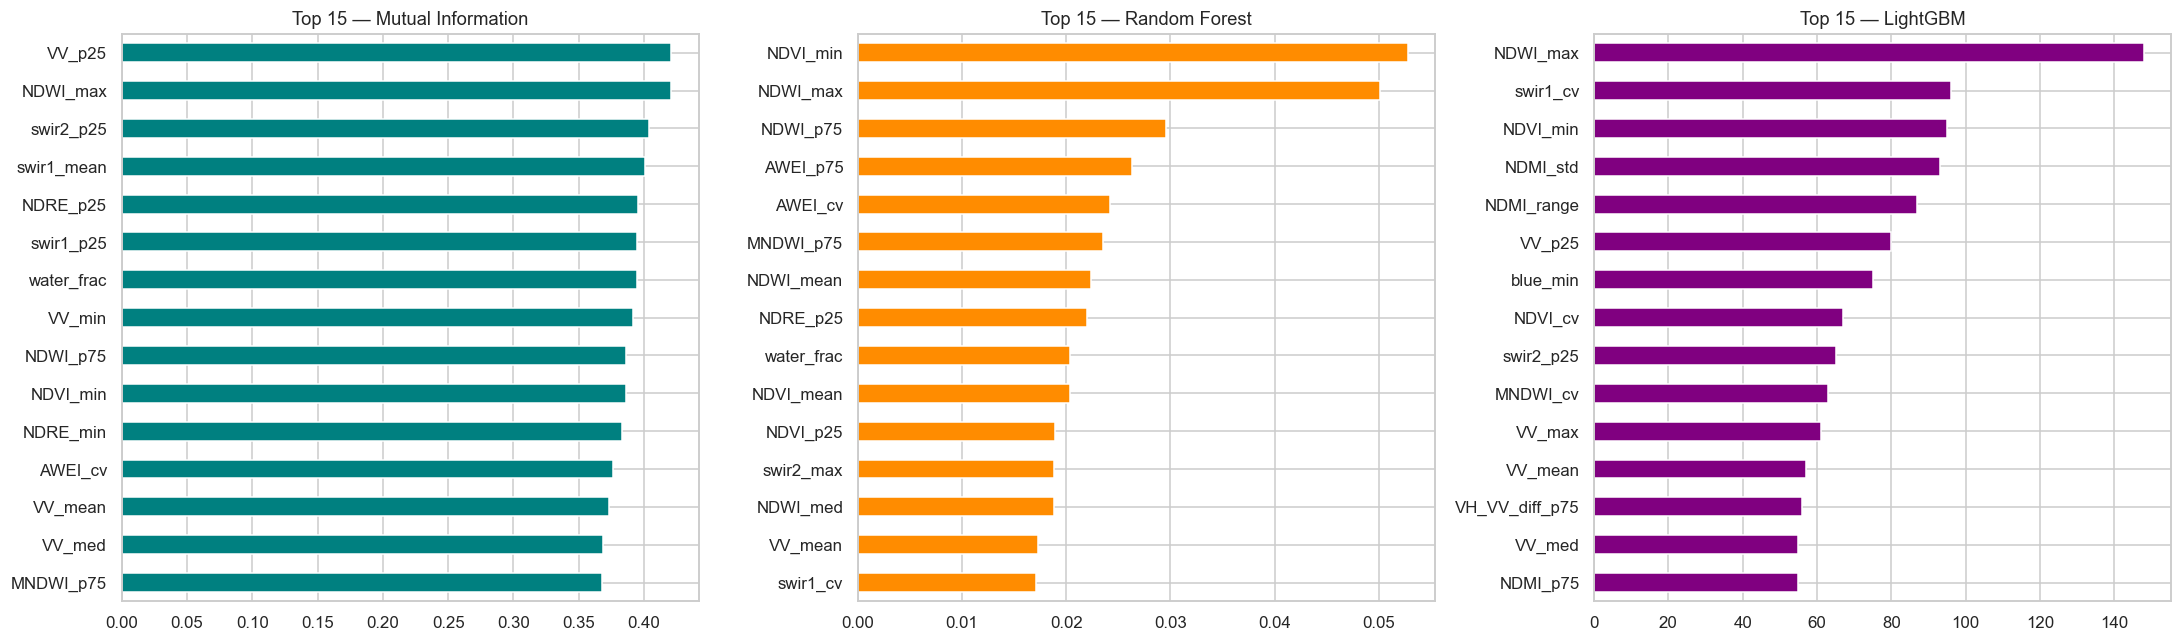

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
mi_s.head(15).sort_values().plot(kind="barh", ax=axes[0], color="teal", title="Top 15 — Mutual Information")
rf_s.head(15).sort_values().plot(kind="barh", ax=axes[1], color="darkorange", title="Top 15 — Random Forest")
lgb_s.head(15).sort_values().plot(kind="barh", ax=axes[2], color="purple", title="Top 15 — LightGBM")
plt.tight_layout()
savefig("feature_importance_comparison")
plt.show()


**👉 À observer**
- Quelles features apparaissent dans le top 10 des **trois** méthodes ? Ce sont
  vos features les plus fiables — à conserver en priorité.
- Une feature en tête d'une seule méthode (ex. très haute en LightGBM mais basse
  ailleurs) peut être un signal réel spécifique aux arbres, ou un artefact
  d'overfitting sur une variable à haute cardinalité — à vérifier en la testant
  isolément (Étape 4 : chaque feature testée indépendamment).
- Comparez ce classement aux observations des sections 4 et 6 (bandes et indices
  visuellement séparateurs). Cohérence = confiance ; divergence = à creuser
  avant de conclure.


## 9. Conclusions de l'EDA

| # | Observation | Hypothèse d'amélioration | Priorité |
|---|---|---|---|
| 1 | Train = 12 mois complets, test = fenêtre consécutive de 4-6 mois + trous nuageux S2. Décalage structurel majeur. | Augmentation par masquage (déjà en place) + n'utiliser que des features agrégées sur mois valides. Recalibrer `mask_window` si un vrai biais de position est confirmé (non confirmé pour l'instant — fin de fenêtre uniforme, pas de biais saisonnier détecté). | Haute |
| 2 | Prior train (40% positifs) probablement différent du prior test (organisateurs l'indiquent). Variable non mesurable avant soumission. | Tester `class_weight` / `scale_pos_weight` pour compenser (jamais le seuil, imposé à 0.5 par le règlement). Comparer F1 OOF avec/sans. | Haute |
| 3 | MNDWI, NDWI, NDVI, NDRE, AWEI séparent très fort les classes (séparabilité 0.90-0.95) mais sont corrélés entre eux à 0.95-0.99 — un seul signal mesuré 5 fois. | Réduire à 2 représentants (ex. MNDWI + NDRE, formules les plus différentes) et comparer le score OOF avant/après simplification. | Moyenne |
| 4 | Ce sont les extrêmes (min/max/p25/p75) qui dominent l'importance des features (Mutual Info, RF, LightGBM), pas les moyennes — un bassin a au moins un mois où l'eau est nettement détectée, même si le reste de l'année est ambigu. | Garder impérativement min/max/percentiles dans toute simplification de features ; ne jamais réduire à mean/std seuls. | Haute |
| 5 | Redondance exacte/quasi-exacte entre bandes brutes : re2≈re3≈nir≈nira (r>0.99), swir1≈swir2 (0.977), blue≈green (0.964), VH_VV_ratio=RVI (r=1.000, doublon strict). | Supprimer VH_VV_ratio (doublon de RVI) ; garder un seul représentant par groupe de bandes corrélées pour les stats brutes agrégées. | Moyenne |
| 6 | Distribution bimodale de la classe 0 sur MNDWI/NDWI/NDVI/NDRE/AWEI : un sous-groupe "autre" ressemble spectralement aux bassins (zones humides, rizières, eau temporaire probable). | Ne pas agir en EDA — à vérifier après le premier modèle via analyse des faux positifs, pour voir si les erreurs correspondent à ce sous-groupe. | Basse (post-modèle) |
| 7 | Séparation classe 0/1 stable sur les 12 mois (pas concentrée sur quelques mois), légère amplification en milieu d'année et resserrement nov-jan sur VH/VV. | Pas de nouvelle feature par mois nécessaire (l'agrégation actuelle capte déjà le signal stable). Point de vigilance : vérifier après entraînement si les erreurs se concentrent sur les fenêtres nov-jan. | Basse (surveillance) |

### Points de vigilance identifiés
- Le décalage de prior train/test (obs. #2) est la variable la moins contrôlable : invérifiable avant soumission Zindi, cause la plus probable d'un écart CV/leaderboard.
- Redondance des bandes/indices (obs. #3, #5) : à traiter par simplification testée en CV, pas en suppression a priori.
- Consensus imparfait entre les 3 méthodes d'importance (ex. AWEI_p75 : rang 4 en RF vs 62 en LightGBM) : ne pas faire de sélection stricte sur un seul classement, utiliser l'avg_rank comme guide seulement.
- Sous-groupe classe 0 bimodal (obs. #6) et fenêtres nov-jan (obs. #7) : à surveiller via analyse d'erreurs post-modèle, pas via l'EDA seule.
